## Checking runs with different policies


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns  
import statsmodels.api as sm

pd.set_option('display.max_columns', None)

### Base Case for comparison

/var/folders/qn/rcpbyl8d6rs2ym4z26w2fk7wyq1ksg/T/ipykernel_39675/3807851016.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  base_and_climate_runs = pd.read_csv('../results/base_and_climate.csv')


Text(0.5, 1.0, 'Base Case (no flooding)')

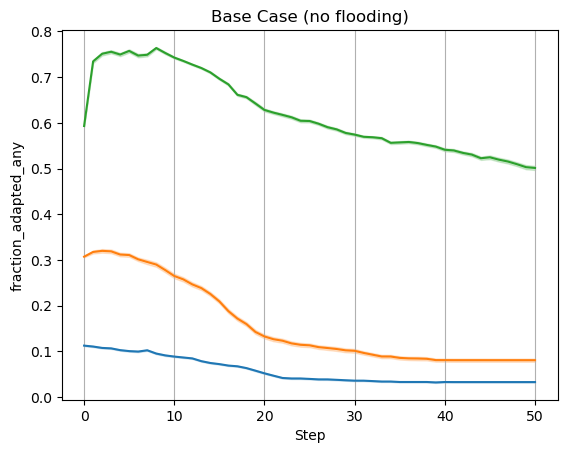

In [2]:
base_and_climate_runs = pd.read_csv('../results/base_and_climate.csv')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'))
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'))

plt.grid(axis = 'x')
# plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Base Case (no flooding)')

### Individual Policies

In [3]:
policy_runs = pd.read_csv('../results/policies.csv')
policy_runs.head()

,Unnamed: 0,Step,seed,nr_households,set_hh_adapted_at_start,prop_inc_for_damage_adaptation,exchange_what,social_norm_calculation,per_HH_adapted_to_SN_prob_midpoint,weight_SN_vs_PMT,opinion_dynamics_model,weight_opinion_others,threshold_similarity_bias,flood_depth_in_m,flood_time,population_density,network_structure_file_path,proportion_ties_added_per_step,proportion_ties_removed_per_step,fraction_ties_added_at_flood,flood_remembrance_period,consider_measure_every_x_steps,minimum_intention_to_consider_measure,worry_increase_with_flood,min_worry_after_flood,damage_reduction,measures_aging,policies_file_path,policy_activation,collect_agent_data,total_savings,savings_low_income,low_income_HH,cumulative_damage,cumulative_damage_no_adaptation,total_damage_experienced,fraction_wet_proofed,fraction_dry_proofed,fraction_adapted_any,fraction_adapted_both,nr_HH_severely_affected,nr_HH_severely_affected_adapted_any,fraction_adapted_any_low_income,avg_intention_SN,avg_intention_PMT_DP,avg_intention_PMT_WP,avg_intention_overall_DP,avg_intention_overall_WP
0,0,0,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.7, 'wet-proofing': 0.7}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_innovation_mid.json,[11],0,115068208.0,2460829.0,144,12632635.0,13264860.0,0.0,0.085,0.068,0.112,0.041,0,0,0.069444,0.0006,0.0804,0.0699,0.0463,0.0378
1,1,1,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.7, 'wet-proofing': 0.7}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_innovation_mid.json,[11],0,117239459.0,2602957.0,144,12645277.0,13264860.0,0.0,0.085,0.072,0.110,0.047,0,0,0.069444,0.0030,0.0811,0.0759,0.0461,0.0433
2,2,2,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.7, 'wet-proofing': 0.7}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_innovation_mid.json,[11],0,119459910.0,2745085.0,144,12659331.0,13264860.0,0.0,0.079,0.071,0.106,0.044,0,0,0.055556,0.0029,0.0813,0.0774,0.0468,0.0437
3,3,3,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.7, 'wet-proofing': 0.7}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_innovation_mid.json,[11],0,121684961.0,2887213.0,144,12669444.0,13264860.0,0.0,0.082,0.068,0.105,0.045,0,0,0.055556,0.0027,0.0763,0.0772,0.0437,0.0435
4,4,4,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.7, 'wet-proofing': 0.7}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_innovation_mid.json,[11],0,123923712.0,3029341.0,144,12686068.0,13264860.0,0.0,0.080,0.066,0.102,0.044,0,0,0.055556,0.0027,0.0789,0.0762,0.0449,0.0429


Variation of 
- flood/no flood
- policies (on, off)
    - innovation (mid, high)
    - subsidies (low, mid, high)
    - communication (low, mid, high)

In [4]:
policy_runs.columns

Index(['Unnamed: 0', 'Step', 'seed', 'nr_households',
       'set_hh_adapted_at_start', 'prop_inc_for_damage_adaptation',
       'exchange_what', 'social_norm_calculation',
       'per_HH_adapted_to_SN_prob_midpoint', 'weight_SN_vs_PMT',
       'opinion_dynamics_model', 'weight_opinion_others',
       'threshold_similarity_bias', 'flood_depth_in_m', 'flood_time',
       'population_density', 'network_structure_file_path',
       'proportion_ties_added_per_step', 'proportion_ties_removed_per_step',
       'fraction_ties_added_at_flood', 'flood_remembrance_period',
       'consider_measure_every_x_steps',
       'minimum_intention_to_consider_measure', 'worry_increase_with_flood',
       'min_worry_after_flood', 'damage_reduction', 'measures_aging',
       'policies_file_path', 'policy_activation', 'collect_agent_data',
       'total_savings', 'savings_low_income', 'low_income_HH',
       'cumulative_damage', 'cumulative_damage_no_adaptation',
       'total_damage_experienced', 'fraction

In [5]:
policy_runs.policies_file_path.unique()

array(['../data/policies/policies_innovation_mid.json',
       '../data/policies/policies_innovation_high.json',
       '../data/policies/policies_subsidies_high.json',
       '../data/policies/policies_comm_high.json',
       '../data/policies/policies_subsidies_mid.json',
       '../data/policies/policies_comm_low_cope.json',
       '../data/policies/policies_comm_mid_cope.json',
       '../data/policies/policies_comm_high_cope.json',
       '../data/policies/policies_comm_mid_norm.json',
       '../data/policies/policies_subsidies_low.json',
       '../data/policies/policies_comm_mid_threat.json',
       '../data/policies/policies_comm_high_threat.json',
       '../data/policies/policies_comm_mid.json',
       '../data/policies/policies_comm_low_norm.json',
       '../data/policies/policies_comm_high_norm.json',
       '../data/policies/policies_comm_low.json',
       '../data/policies/policies_comm_low_threat.json'], dtype=object)

#### Communication Policy

Visualizing the effects of the communication policy

Text(0.5, 1.0, 'Coommunication Policy (no flood)')

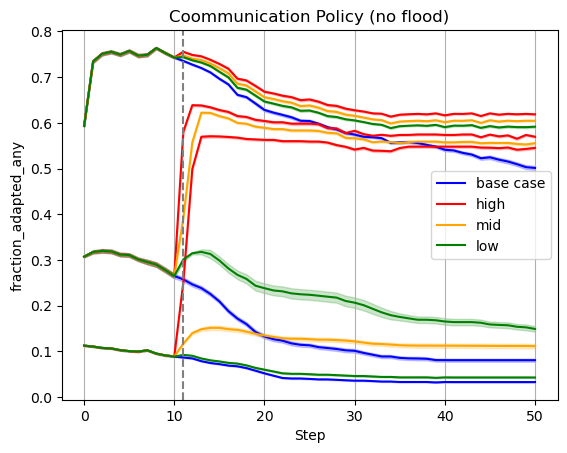

In [6]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')



plt.grid(axis = 'x')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Coommunication Policy (no flood)')

- depending on the starting conditions, the communication policy can 
    - "hold the line" (0.6 initial adaptation), regardless of it's input
    - lead to high jumps ("high") 
- "low" is less effective the lower the inital starting conditions and doesn't manage to keep up the adaptation rate


Text(0.5, 1.0, 'Communication Policy (flood)')

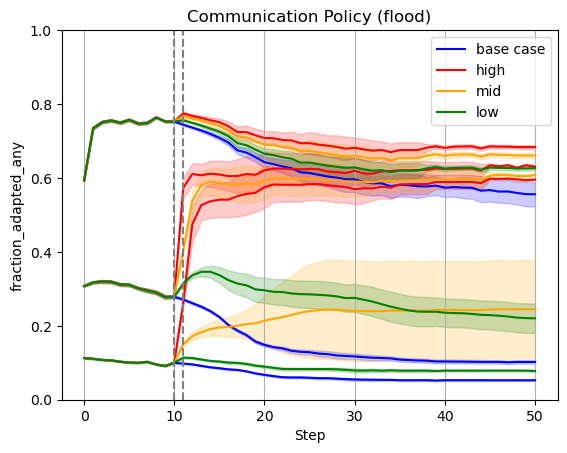

In [7]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (flood)')

Text(0.5, 1.0, 'Communication Policy (flood)')

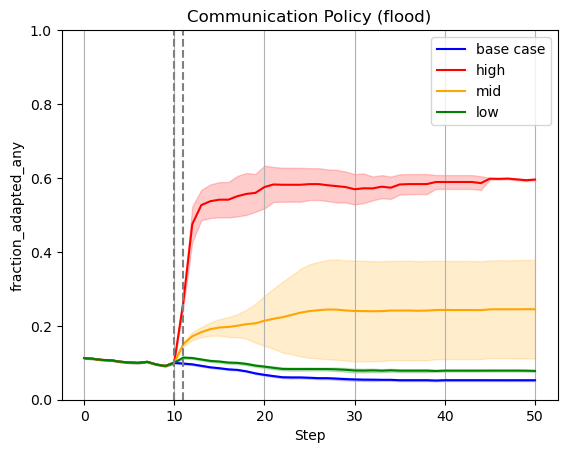

In [8]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low', color = 'green')

plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (flood)')

- flooding adds more spread to the results
- apart from that not qualitatively different

Text(0.5, 1.0, 'Communication Policy (flood)')

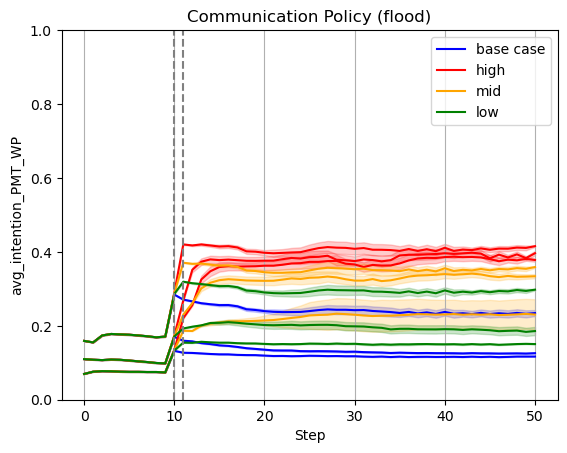

In [9]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_PMT_WP', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_PMT_WP', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_PMT_WP',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_PMT_WP', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_PMT_WP', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_PMT_WP',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_PMT_WP', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_PMT_WP', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_PMT_WP',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_PMT_WP', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_PMT_WP', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_PMT_WP',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (flood)')

Text(0.5, 1.0, 'Communication Policy (flood)')

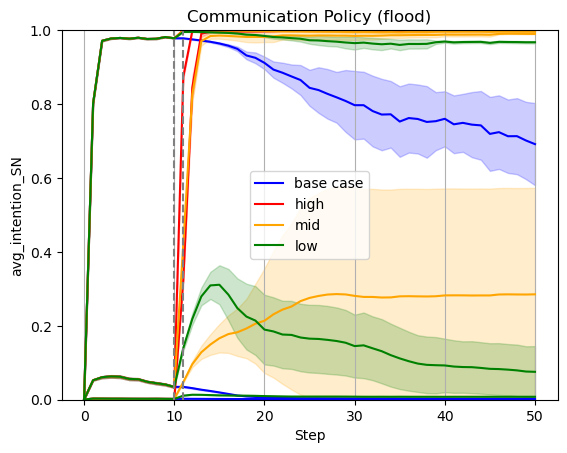

In [10]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_SN', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_SN', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_SN',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_SN', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_SN', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_SN',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_SN', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_SN', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_SN',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_SN', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_SN', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_SN',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (flood)')

Text(0.5, 1.0, 'Communication Policy (flood)')

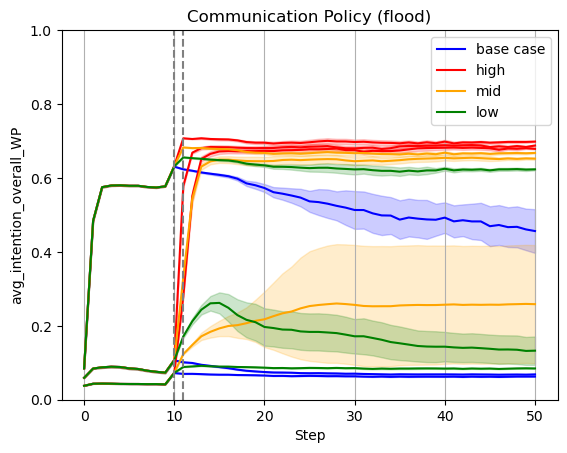

In [11]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (flood)')

##### Communication policy broken down into parts (threat communication, coping communication, norm perception change)

Text(0.5, 1.0, 'Coommunication Policy (no flood)')

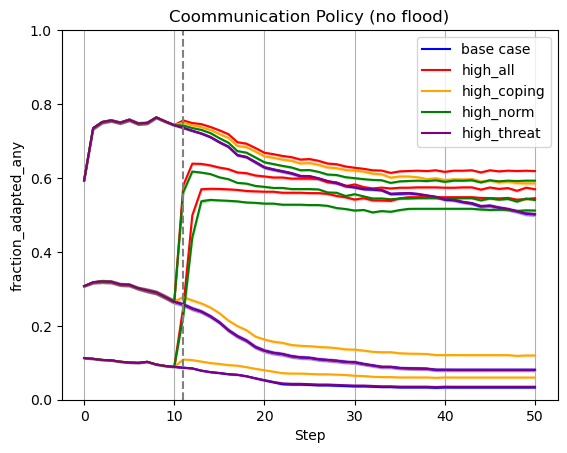

In [12]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high_all', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high_coping', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high_norm', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high_threat', color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'purple')

plt.grid(axis = 'x')
plt.ylim(0,1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Coommunication Policy (no flood)')

- threat basically no effect
- coping small effect
- norm has most effect
- all: effect adds up - norm by far most important


Text(0.5, 1.0, 'Communication Policy (flood)')

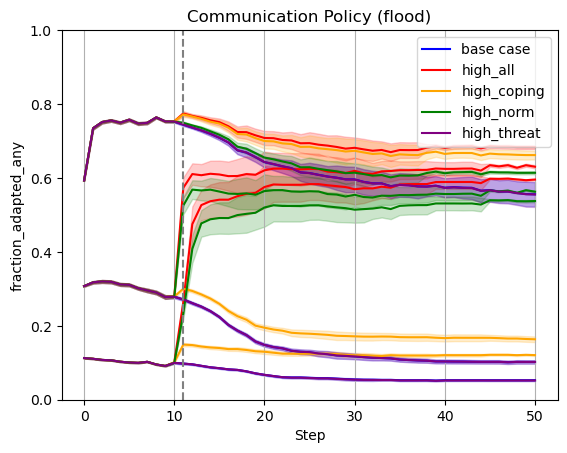

In [13]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high_all', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high_coping', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high_norm', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high_threat', color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'purple')

plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (flood)')

Text(0.5, 1.0, 'Communication Policy (no flood)')

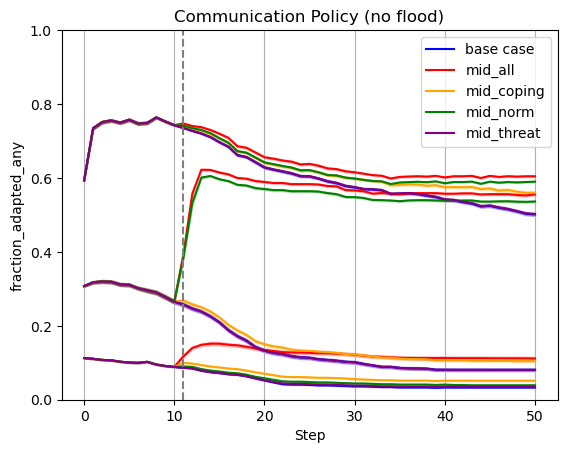

In [14]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid_all', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_cope.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid_coping', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_cope.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_cope.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_norm.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid_norm', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_norm.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_norm.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_threat.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid_threat', color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_threat.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_threat.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'purple')

plt.grid(axis = 'x')
plt.ylim(0,1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (no flood)')

Text(0.5, 1.0, 'Communication Policy (no flood)')

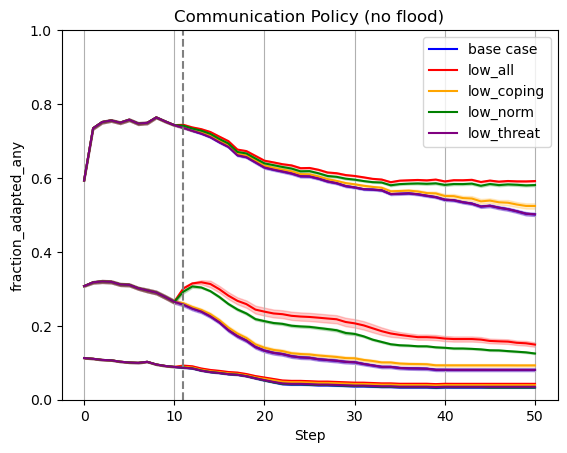

In [15]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low_all', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_cope.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low_coping', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_cope.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_cope.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_norm.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low_norm', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_norm.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_norm.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_threat.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low_threat', color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_threat.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_threat.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'purple')

plt.grid(axis = 'x')
plt.ylim(0,1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (no flood)')

Text(0.5, 1.0, 'Communication Policy (no flood)')

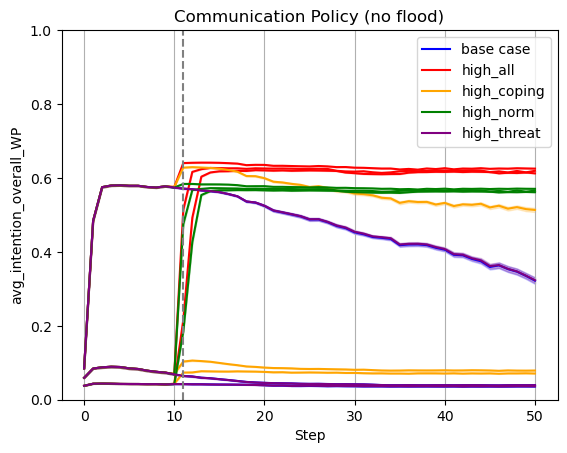

In [16]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'high_all', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'high_coping', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_cope.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'high_norm', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_norm.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'green')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'high_threat', color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_high_threat.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'purple')

plt.grid(axis = 'x')
plt.ylim(0,1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (no flood)')

Text(0.5, 1.0, 'Communication Policy (no flood)')

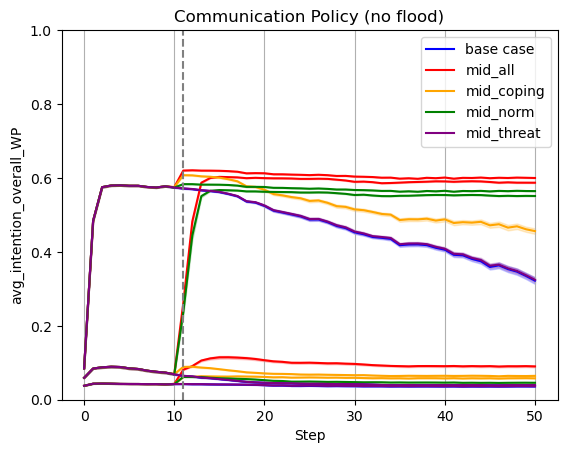

In [17]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'mid_all', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_cope.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'mid_coping', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_cope.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_cope.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_norm.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'mid_norm', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_norm.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_norm.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'green')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_threat.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'mid_threat', color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_threat.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_mid_threat.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'purple')

plt.grid(axis = 'x')
plt.ylim(0,1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (no flood)')

Text(0.5, 1.0, 'Communication Policy (no flood)')

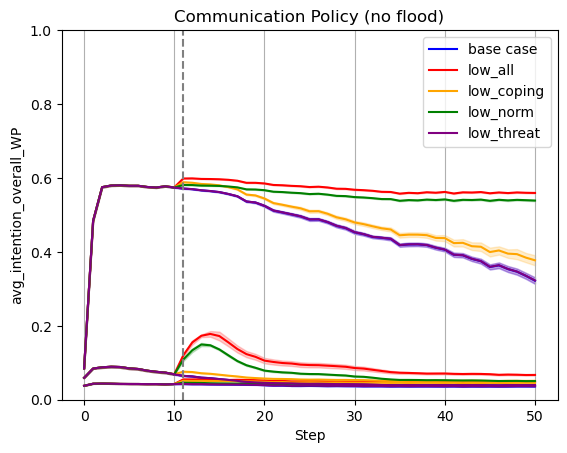

In [18]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'low_all', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_cope.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'low_coping', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_cope.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_cope.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_norm.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'low_norm', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_norm.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_norm.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'green')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_threat.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), label = 'low_threat', color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_threat.json')], x='Step', y='avg_intention_overall_WP', errorbar=('sd'), legend = False, color = 'purple')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_comm_low_threat.json')], x='Step', y='avg_intention_overall_WP',  errorbar=('sd'), legend = False, color = 'purple')

plt.grid(axis = 'x')
plt.ylim(0,1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Communication Policy (no flood)')

##### Variance decomposition
Checking how much the change in adaptaiton is due to the changes in intention (social norm vs PMT)


In [19]:
variance_df = policy_runs.loc[policy_runs['Step'] == 50]

In [20]:
variance_df['flood_occured'] = (variance_df['flood_time'] != '[99]').astype(int)

/var/folders/qn/rcpbyl8d6rs2ym4z26w2fk7wyq1ksg/T/ipykernel_39675/2529764423.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  variance_df['flood_occured'] = (variance_df['flood_time'] != '[99]').astype(int)


In [21]:
variance_df.tail()

,Unnamed: 0,Step,seed,nr_households,set_hh_adapted_at_start,prop_inc_for_damage_adaptation,exchange_what,social_norm_calculation,per_HH_adapted_to_SN_prob_midpoint,weight_SN_vs_PMT,opinion_dynamics_model,weight_opinion_others,threshold_similarity_bias,flood_depth_in_m,flood_time,population_density,network_structure_file_path,proportion_ties_added_per_step,proportion_ties_removed_per_step,fraction_ties_added_at_flood,flood_remembrance_period,consider_measure_every_x_steps,minimum_intention_to_consider_measure,worry_increase_with_flood,min_worry_after_flood,damage_reduction,measures_aging,policies_file_path,policy_activation,collect_agent_data,total_savings,savings_low_income,low_income_HH,cumulative_damage,cumulative_damage_no_adaptation,total_damage_experienced,fraction_wet_proofed,fraction_dry_proofed,fraction_adapted_any,fraction_adapted_both,nr_HH_severely_affected,nr_HH_severely_affected_adapted_any,fraction_adapted_any_low_income,avg_intention_SN,avg_intention_PMT_DP,avg_intention_PMT_WP,avg_intention_overall_DP,avg_intention_overall_WP,flood_occured
389945,389945,50,12394,1000,0.6,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]","[10, 25, 35, 42]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_low_cope.json,[11],0,166525246.0,2033652.0,141,10277376.0,13398974.0,39419641.0,0.509,0.494,0.566,0.437,0,0,0.404255,0.7379,0.4466,0.2714,0.5628,0.4991,1
389996,389996,50,12394,1000,0.6,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]","[10, 25, 35, 42]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_mid_cope.json,[11],0,165492643.0,2013318.0,141,10053853.0,13398974.0,38845381.0,0.558,0.534,0.611,0.481,0,0,0.418440,0.8507,0.4949,0.3310,0.6442,0.5846,1
390047,390047,50,12394,1000,0.6,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]","[10, 25, 35, 42]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_low_threat.json,[11],0,167021186.0,2044380.0,141,10375365.0,13398974.0,39566378.0,0.487,0.474,0.546,0.415,0,0,0.404255,0.6824,0.4197,0.2263,0.5217,0.4496,1
390098,390098,50,12394,1000,0.6,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]","[10, 25, 35, 42]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_mid_threat.json,[11],0,167069854.0,2044380.0,141,10385375.0,13398974.0,39598909.0,0.485,0.472,0.544,0.413,0,0,0.404255,0.6759,0.4190,0.2263,0.5177,0.4463,1
390149,390149,50,12394,1000,0.6,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]","[10, 25, 35, 42]","[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_mid_norm.json,[11],0,165971369.0,2001008.0,141,10154750.0,13398974.0,39303328.0,0.542,0.516,0.591,0.467,0,0,0.411348,0.9880,0.4655,0.2357,0.6909,0.6055,1


In [22]:
X1 = variance_df[['avg_intention_PMT_WP', 'avg_intention_PMT_DP', 'avg_intention_SN']]
X1 = sm.add_constant(X1)

X2 = variance_df[['avg_intention_PMT_WP', 'avg_intention_PMT_DP', 'avg_intention_SN', 'flood_occured']]
X2 = sm.add_constant(X2)

y = variance_df['fraction_adapted_any']

m1 = sm.OLS(y, X1).fit()
m2 = sm.OLS(y, X2).fit()

r2_1 = m1.rsquared
r2_2 = m2.rsquared
delta_r2 = r2_2 - r2_1

print('R1squared (no flood accounted for)', r2_1)
print('R2squared (incl flood occurence)', r2_2)

R1squared (no flood accounted for) 0.9969943937894636
R2squared (incl flood occurence) 0.9971605389695845


In [23]:
# Full model
X_full = sm.add_constant(variance_df[['avg_intention_PMT_WP', 'avg_intention_PMT_DP', 'avg_intention_SN', 'flood_occured']])
m_full = sm.OLS(y, X_full).fit()

# Remove intention_PMT
X_no_PMT = sm.add_constant(variance_df[['avg_intention_SN', 'flood_occured']])
m_no_PMT = sm.OLS(y, X_no_PMT).fit()

# Remove intention_SN
X_no_SN = sm.add_constant(variance_df[['avg_intention_PMT_WP', 'avg_intention_PMT_DP', 'flood_occured']])
m_no_SN = sm.OLS(y, X_no_SN).fit()

# Remove flood_occurrence
X_no_flood = sm.add_constant(variance_df[['avg_intention_PMT_WP', 'avg_intention_PMT_DP', 'avg_intention_SN']])
m_no_flood = sm.OLS(y, X_no_flood).fit()

# Compute contributions
contrib_PMT = m_full.rsquared - m_no_PMT.rsquared
contrib_SN = m_full.rsquared - m_no_SN.rsquared
contrib_flood = m_full.rsquared - m_no_flood.rsquared

print("Contribution PMT:", contrib_PMT)
print("Contribution SN:", contrib_SN)
print("Contribution flood:", contrib_flood)
print("Total R²:", m_full.rsquared)

print(m_full.summary())


Contribution PMT: 0.06948635362559352
Contribution SN: 0.00129954647880548
Contribution flood: 0.00016614518012081358
Total R²: 0.9971605389695845
                             OLS Regression Results                             
Dep. Variable:     fraction_adapted_any   R-squared:                       0.997
Model:                              OLS   Adj. R-squared:                  0.997
Method:                   Least Squares   F-statistic:                 6.712e+05
Date:                  Wed, 09 Sep 2026   Prob (F-statistic):               0.00
Time:                          14:06:49   Log-Likelihood:                 22468.
No. Observations:                  7650   AIC:                        -4.493e+04
Df Residuals:                      7645   BIC:                        -4.489e+04
Df Model:                             4                                         
Covariance Type:              nonrobust                                         
                           coef    std err 

In [24]:
variance_df[['avg_intention_PMT_WP', 'avg_intention_PMT_DP', 'avg_intention_SN', 'fraction_adapted_any']].corr()

,avg_intention_PMT_WP,avg_intention_PMT_DP,avg_intention_SN,fraction_adapted_any
avg_intention_PMT_WP,1.000000,0.804527,0.727098,0.769620
avg_intention_PMT_DP,0.804527,1.000000,0.969494,0.996401
avg_intention_SN,0.727098,0.969494,1.000000,0.962656
fraction_adapted_any,0.769620,0.996401,0.962656,1.000000


#### Subsidy Policy

Text(0.5, 1.0, 'Subsidies Policy (no flood)')

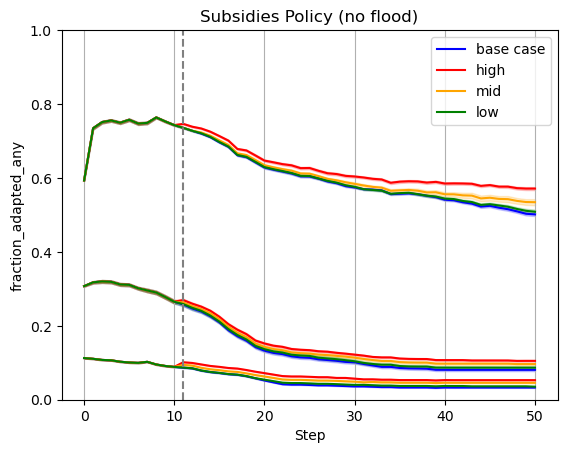

In [25]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Subsidies Policy (no flood)')

Text(0.5, 1.0, 'Subsidies Policy (flood)')

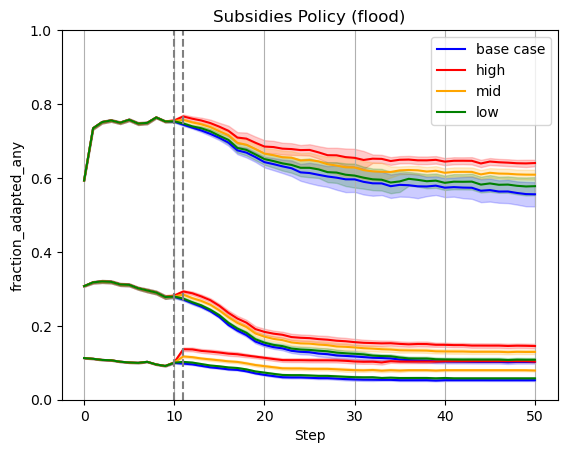

In [26]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.title('Subsidies Policy (flood)')

Text(0.5, 1.0, 'Subsidies Policy (flood)')

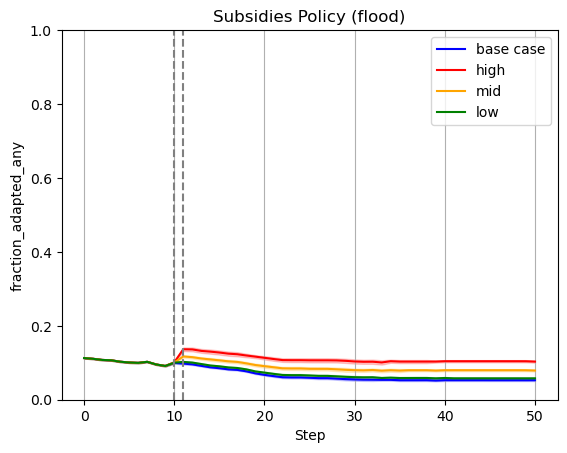

In [27]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low', color = 'green')


plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.title('Subsidies Policy (flood)')

In [28]:
policy_runs.flood_time.unique()

array(['[99]', '[10]', '[10, 25, 35, 42]'], dtype=object)

Text(0.5, 1.0, 'Subsidies Policy (flood (4 times))')

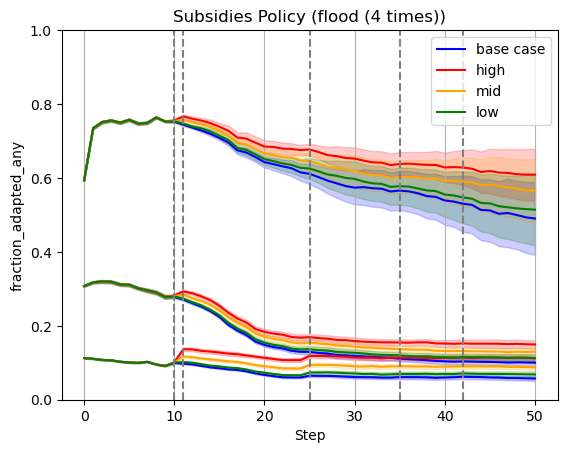

In [29]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(10, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(25, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(35, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(42, 0, 1, color = 'grey', linestyle = '--')
plt.title('Subsidies Policy (flood (4 times))')

Text(0.5, 1.0, 'Subsidies Policy (flood (4 times))')

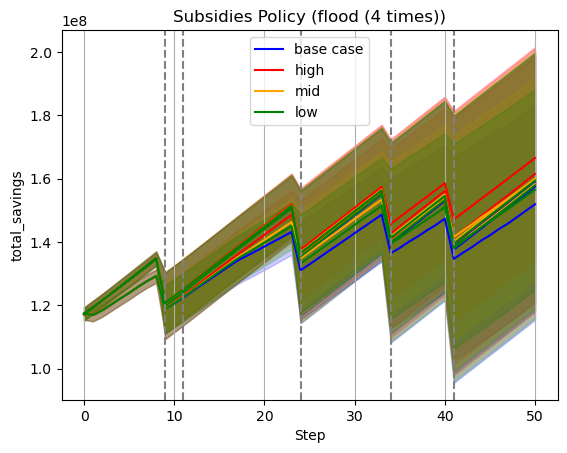

In [30]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='total_savings', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='total_savings', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='total_savings',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_savings', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_savings', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_savings',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_savings', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_savings', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_savings',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_savings', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_savings', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_savings',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
# plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(9, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(24, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(34, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(41, 0, 1, color = 'grey', linestyle = '--')
plt.title('Subsidies Policy (flood (4 times))')

Text(0.5, 1.0, 'Subsidies Policy (flood (4 times))')

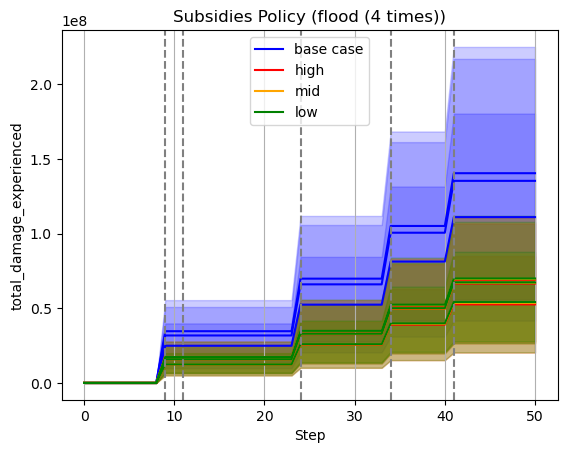

In [31]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='total_damage_experienced', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='total_damage_experienced', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='total_damage_experienced',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_damage_experienced', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_damage_experienced', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_damage_experienced',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_damage_experienced', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_damage_experienced', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_damage_experienced',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_damage_experienced', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_damage_experienced', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_damage_experienced',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
# plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(9, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(24, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(34, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(41, 0, 1, color = 'grey', linestyle = '--')
plt.title('Subsidies Policy (flood (4 times))')

Text(0.5, 1.0, 'Subsidies Policy (flood)')

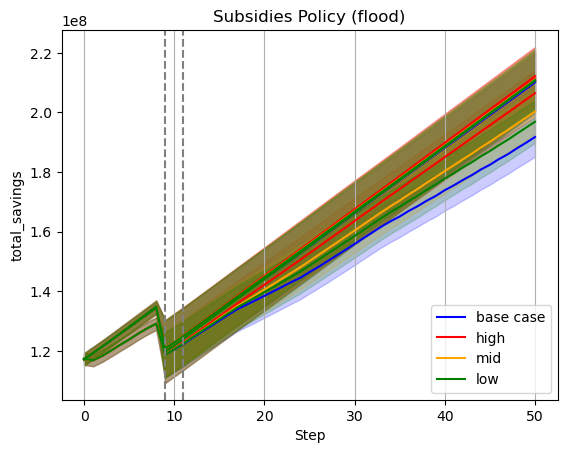

In [32]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='total_savings', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='total_savings', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='total_savings',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_savings', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_savings', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_high.json')], x='Step', y='total_savings',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_savings', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_savings', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_mid.json')], x='Step', y='total_savings',  errorbar=('sd'), legend = False, color = 'orange')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_savings', errorbar=('sd'), label = 'low', color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_savings', errorbar=('sd'), legend = False, color = 'green')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_subsidies_low.json')], x='Step', y='total_savings',  errorbar=('sd'), legend = False, color = 'green')


plt.grid(axis = 'x')
# plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.axvline(9, 0, 1, color = 'grey', linestyle = '--')
plt.title('Subsidies Policy (flood)')

- damage experienced reduced by the subsidies measure because of the delta in adaptaiton
- savings recover faster with subsidies

#### Innovation policy

Text(0.5, 1.0, 'Innovation Policy (no flood)')

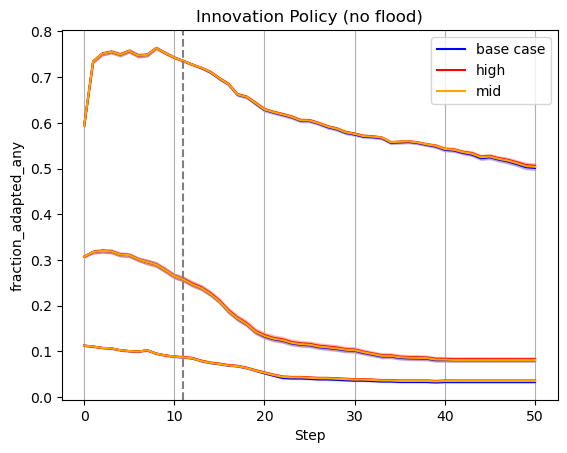

In [33]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

plt.grid(axis = 'x')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Innovation Policy (no flood)')

Text(0.5, 1.0, 'Innovation Policy (no flood)')

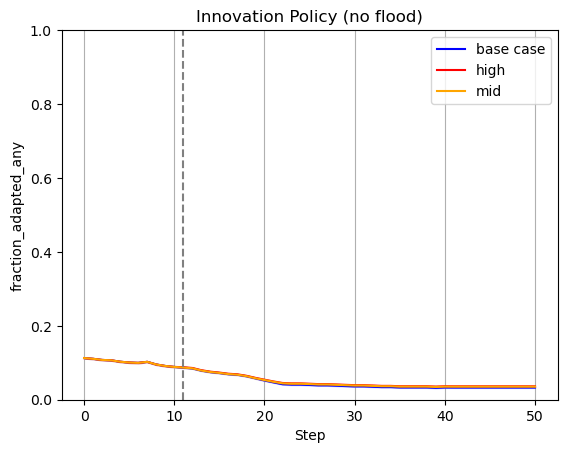

In [34]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 3, 3, 3, 3]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')

plt.grid(axis = 'x')
plt.ylim(0, 1)
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Innovation Policy (no flood)')

In [35]:
policy_runs['damage_reduction'] = (policy_runs['cumulative_damage_no_adaptation']-policy_runs['cumulative_damage'])
base_and_climate_runs['damage_reduction'] = (base_and_climate_runs['cumulative_damage_no_adaptation']-base_and_climate_runs['cumulative_damage'])

Text(0.5, 1.0, 'Innovation Policy (no flood)')

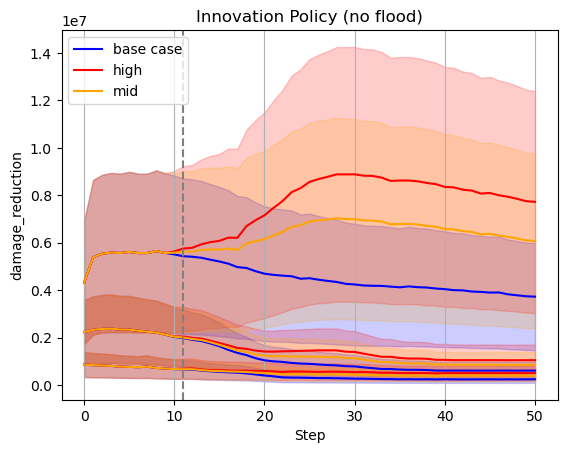

In [36]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='damage_reduction', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='damage_reduction', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='damage_reduction',  errorbar=('sd'), legend = False, color = 'blue')


sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='damage_reduction', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='damage_reduction', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='damage_reduction',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='damage_reduction', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='damage_reduction', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[99]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='damage_reduction',  errorbar=('sd'), legend = False, color = 'orange')

plt.grid(axis = 'x')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Innovation Policy (no flood)')

Text(0.5, 1.0, 'Innovation Policy (flood)')

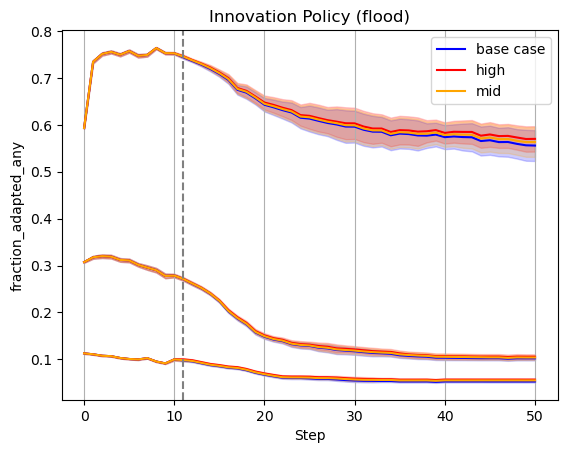

In [37]:
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'base case', color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'blue')
sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'blue')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'high', color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'red')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_high.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'red')

sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == 'False') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'mid', color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='fraction_adapted_any', errorbar=('sd'), legend = False, color = 'orange')
sns.lineplot(data=policy_runs.loc[(policy_runs['set_hh_adapted_at_start'] == '0.6') & (policy_runs['flood_time'] == '[10]') & (policy_runs['policy_activation'] == '[11]')& (policy_runs['policies_file_path'] == '../data/policies/policies_innovation_mid.json')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), legend = False, color = 'orange')

plt.grid(axis = 'x')
plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
plt.title('Innovation Policy (flood)')

- innovation policy not really effective on its own
- again, the flood event leads to more spread in results
- no effect on damage experienced


### Policy Combination

In [38]:
policy_comb_runs = pd.read_csv('../results/policies_comb.csv')
policy_comb_runs.head()

,Unnamed: 0,Step,seed,nr_households,set_hh_adapted_at_start,prop_inc_for_damage_adaptation,exchange_what,social_norm_calculation,per_HH_adapted_to_SN_prob_midpoint,weight_SN_vs_PMT,opinion_dynamics_model,weight_opinion_others,threshold_similarity_bias,flood_depth_in_m,flood_time,population_density,network_structure_file_path,proportion_ties_added_per_step,proportion_ties_removed_per_step,fraction_ties_added_at_flood,flood_remembrance_period,consider_measure_every_x_steps,minimum_intention_to_consider_measure,worry_increase_with_flood,min_worry_after_flood,damage_reduction,measures_aging,policies_file_path,policy_activation,collect_agent_data,total_savings,savings_low_income,low_income_HH,cumulative_damage,cumulative_damage_no_adaptation,total_damage_experienced,fraction_wet_proofed,fraction_dry_proofed,fraction_adapted_any,fraction_adapted_both,nr_HH_severely_affected,nr_HH_severely_affected_adapted_any,fraction_adapted_any_low_income,avg_intention_SN,avg_intention_PMT_DP,avg_intention_PMT_WP,avg_intention_overall_DP,avg_intention_overall_WP
0,0,0,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_sub_HM.json,[11],0,115068208.0,2460829.0,144,12632635.0,13264860.0,0.0,0.085,0.068,0.112,0.041,0,0,0.069444,0.0006,0.0804,0.0699,0.0463,0.0378
1,1,1,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_sub_HM.json,[11],0,117239459.0,2602957.0,144,12645277.0,13264860.0,0.0,0.085,0.072,0.110,0.047,0,0,0.069444,0.0030,0.0811,0.0759,0.0461,0.0433
2,2,2,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_sub_HM.json,[11],0,119459910.0,2745085.0,144,12659331.0,13264860.0,0.0,0.079,0.071,0.106,0.044,0,0,0.055556,0.0029,0.0813,0.0774,0.0468,0.0437
3,3,3,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_sub_HM.json,[11],0,121684961.0,2887213.0,144,12669444.0,13264860.0,0.0,0.082,0.068,0.105,0.045,0,0,0.055556,0.0027,0.0763,0.0772,0.0437,0.0435
4,4,4,12345,1000,False,0.05,threat+coping,all,0.5,empirical,similarity_biased,0.5,0.2,"[99, 1, 1, 1, 1]",[99],"[[0, 50, 50, 50, 50], [0, 50, 50, 50, 50], [0,...",../data/processed/network_structures/network_e...,0,0,0,5,1,0.05,0.3,0.1,"{'dry-proofing': 0.5, 'wet-proofing': 0.4}","{'dry-proofing': 20, 'wet-proofing': 20}",../data/policies/policies_comm_sub_HM.json,[11],0,123923712.0,3029341.0,144,12686068.0,13264860.0,0.0,0.080,0.066,0.102,0.044,0,0,0.055556,0.0027,0.0789,0.0762,0.0449,0.0429


In [39]:
# policy column
policy_comb_runs['policy'] = policy_comb_runs.apply(lambda row: 'None' if (isinstance(row['policies_file_path'], str) and row['policies_file_path'].endswith('policies_null.json')) or str(row['policy_activation']).strip() == '[99]' else (row['policies_file_path'].split('/data/policies/')[-1].replace('.json', '') if isinstance(row['policies_file_path'], str) and '/data/policies/' in row['policies_file_path'] else None), axis=1)


In [40]:
policy_comb_runs.policy.unique()

array(['policies_comm_sub_HM', 'policies_comm_sub_MM',
       'policies_comm_sub_LH', 'policies_comm_sub_ML',
       'policies_comm_sub_HL', 'policies_comm_sub_LL',
       'policies_comm_sub_inn_HHH', 'policies_comm_sub_LM',
       'policies_comm_sub_HH', 'policies_comm_sub_inn_LLM',
       'policies_comm_sub_MH'], dtype=object)

In [41]:
policy_comb_runs.policies_file_path.unique()

array(['../data/policies/policies_comm_sub_HM.json',
       '../data/policies/policies_comm_sub_MM.json',
       '../data/policies/policies_comm_sub_LH.json',
       '../data/policies/policies_comm_sub_ML.json',
       '../data/policies/policies_comm_sub_HL.json',
       '../data/policies/policies_comm_sub_LL.json',
       '../data/policies/policies_comm_sub_inn_HHH.json',
       '../data/policies/policies_comm_sub_LM.json',
       '../data/policies/policies_comm_sub_HH.json',
       '../data/policies/policies_comm_sub_inn_LLM.json',
       '../data/policies/policies_comm_sub_MH.json'], dtype=object)

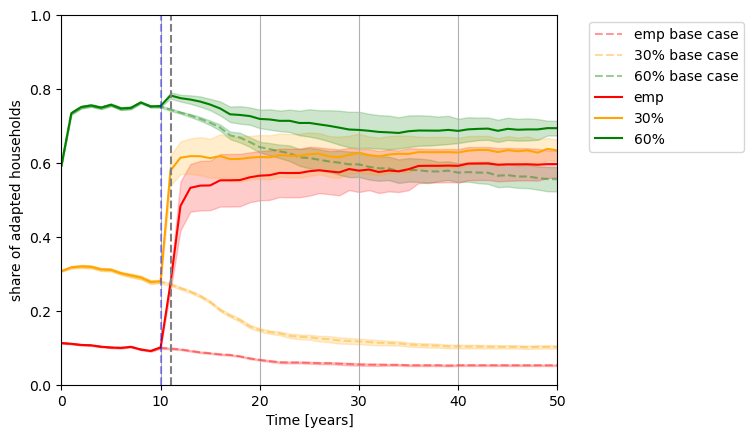

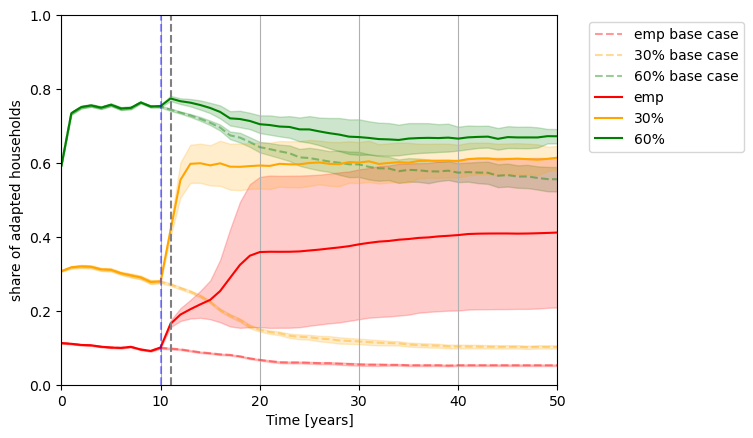

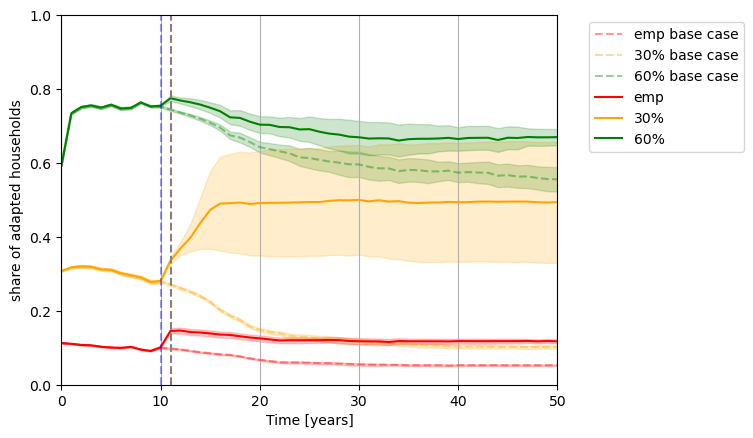

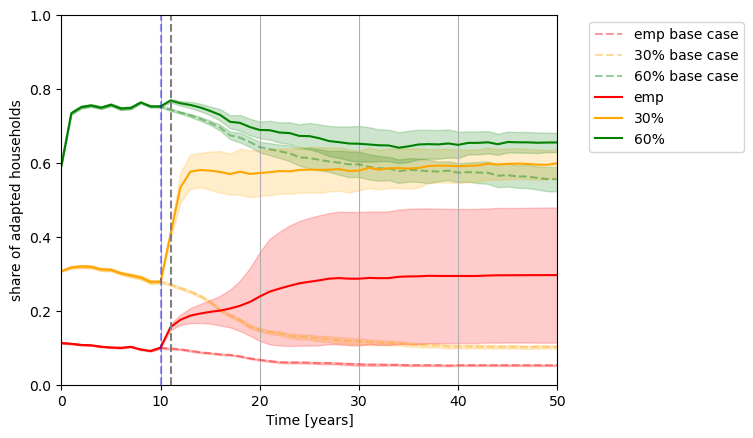

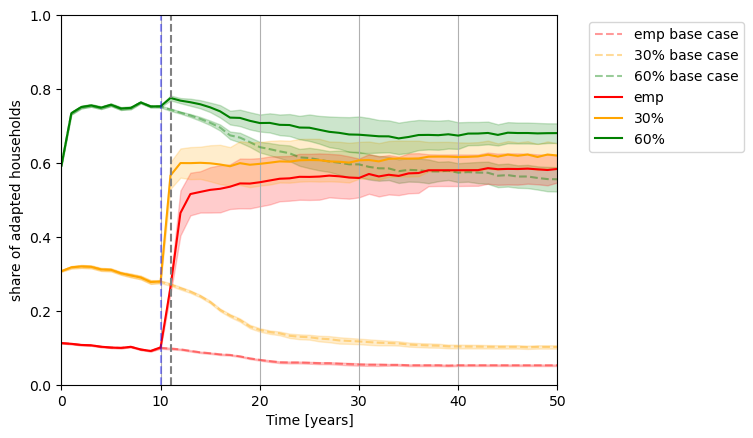

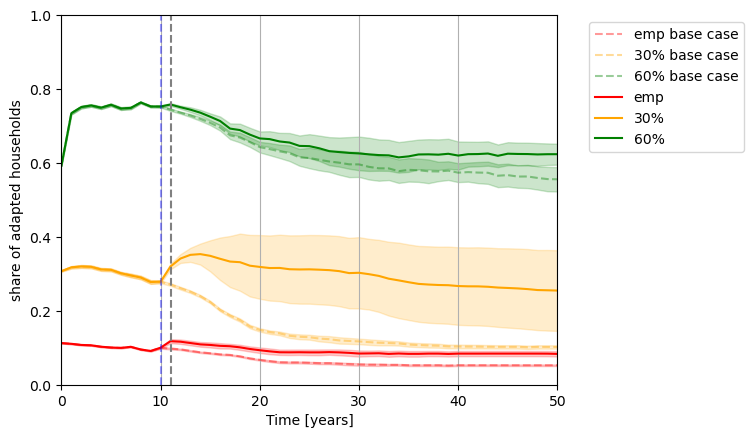

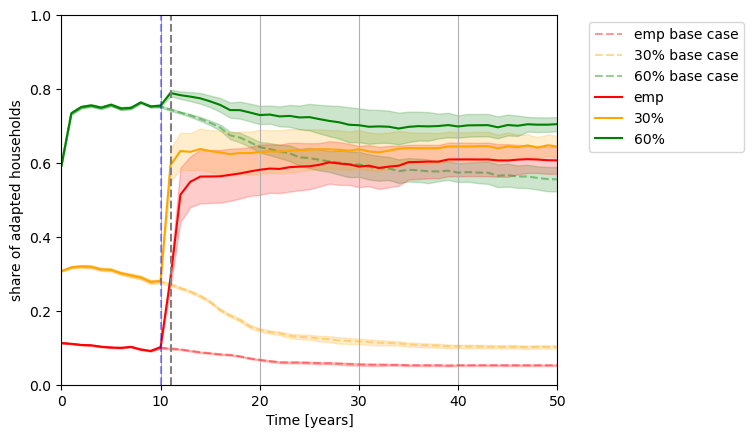

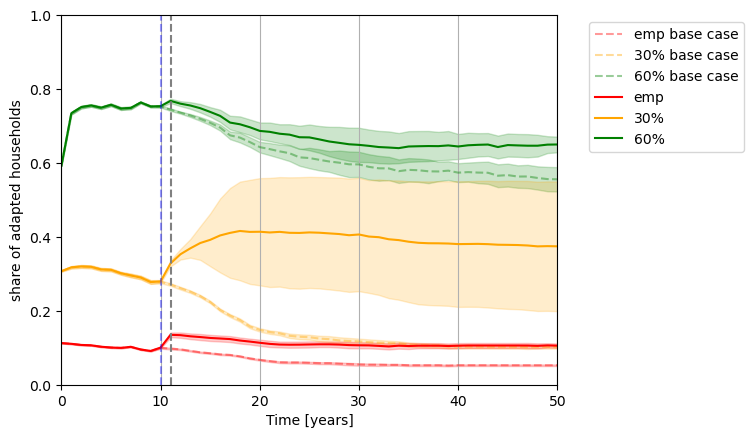

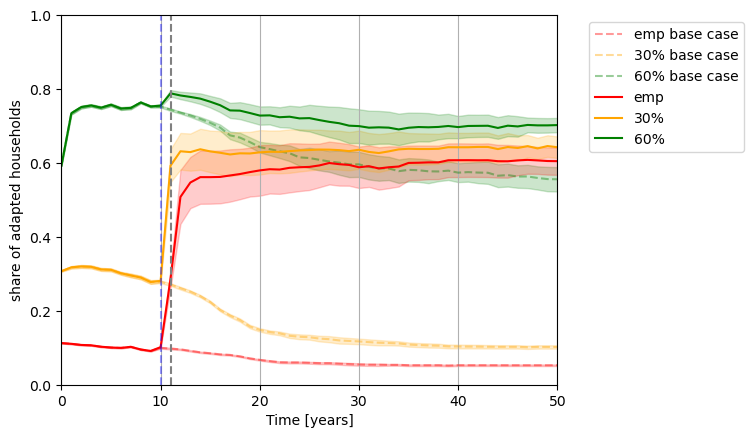

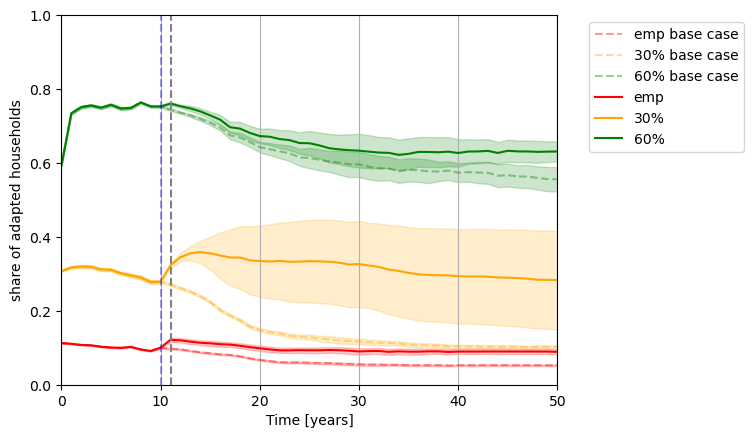

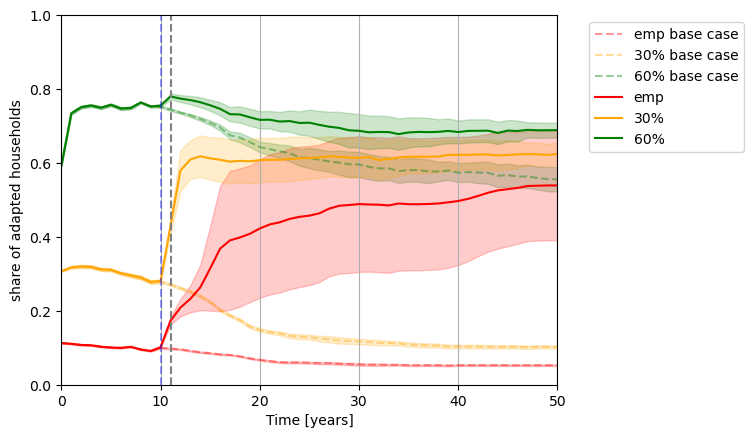

In [42]:
for policy in policy_comb_runs.policy.unique():
    plt.figure()
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'emp base case', color = 'red', alpha = 0.4, linestyle = '--')
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = '30% base case', color = 'orange', alpha = 0.4, linestyle = '--')
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), label = '60% base case', color = 'green', alpha = 0.4, linestyle = '--')

    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == 'False') & (policy_comb_runs['flood_time'] == '[10]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policy'] == policy)], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'emp', color = 'red')
    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_comb_runs['flood_time'] == '[10]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policy'] == policy)], x='Step', y='fraction_adapted_any', errorbar=('sd'),  label = '30%', color = 'orange')
    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == '0.6') & (policy_comb_runs['flood_time'] == '[10]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policy'] == policy)], x='Step', y='fraction_adapted_any',  errorbar=('sd'),  label = '60%', color = 'green')

    plt.grid(axis = 'x')
    plt.ylim(0, 1)
    plt.xlim(0, 50)
    plt.xlabel('Time [years]')
    plt.ylabel('share of adapted households')
    plt.axvline(10, 0, 1, color = 'blue', alpha = 0.4, linestyle = '--')
    plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    # plt.title(policy)
    plt.savefig(f'../reports/figures/p_comb_{policy}_1_flood.png', bbox_inches='tight')
    # plt.show()

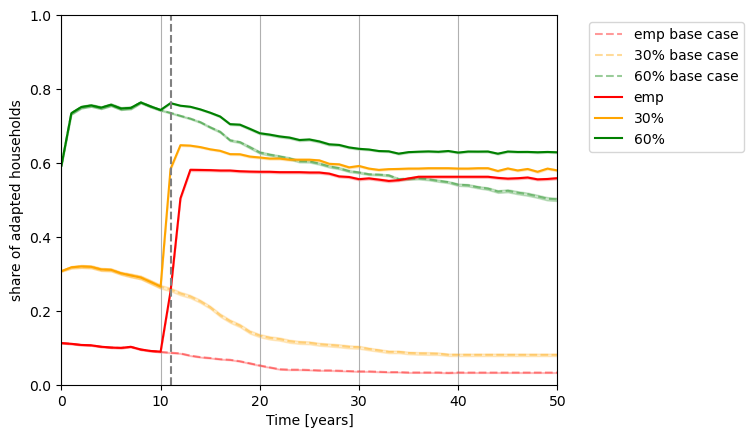

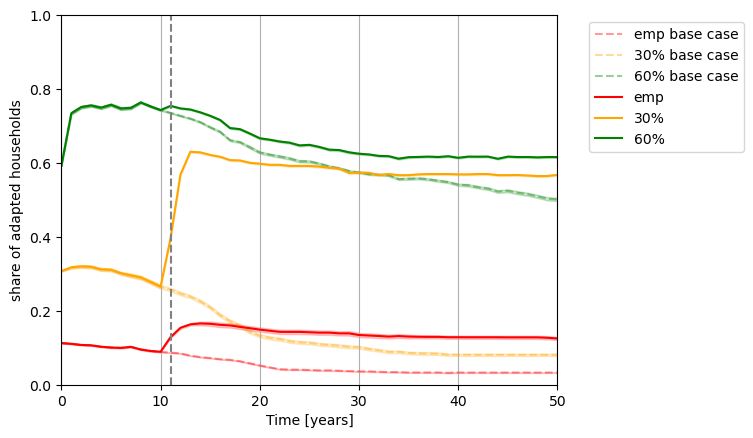

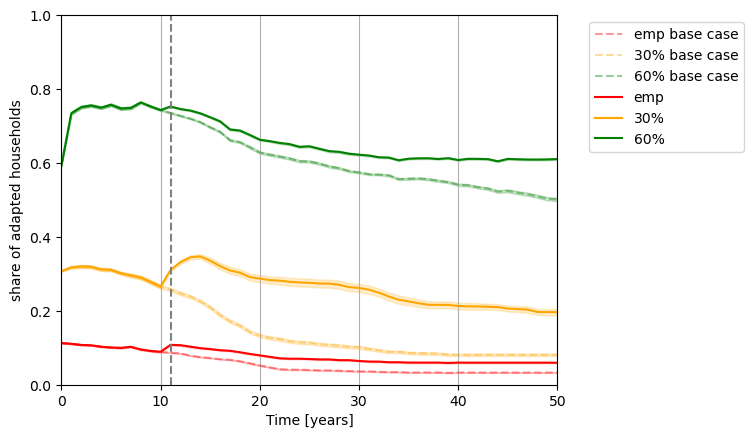

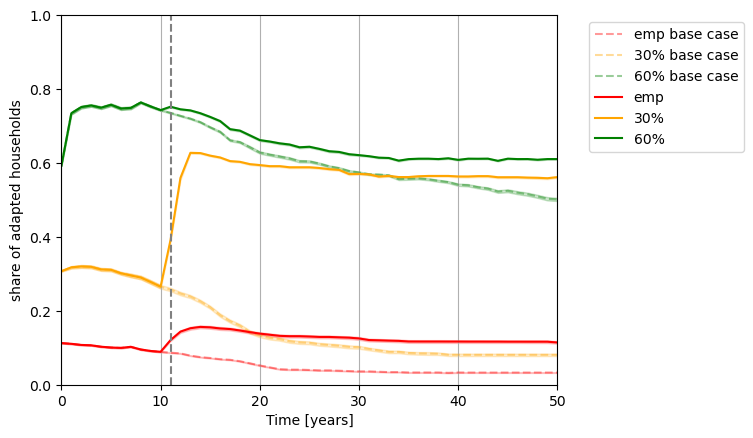

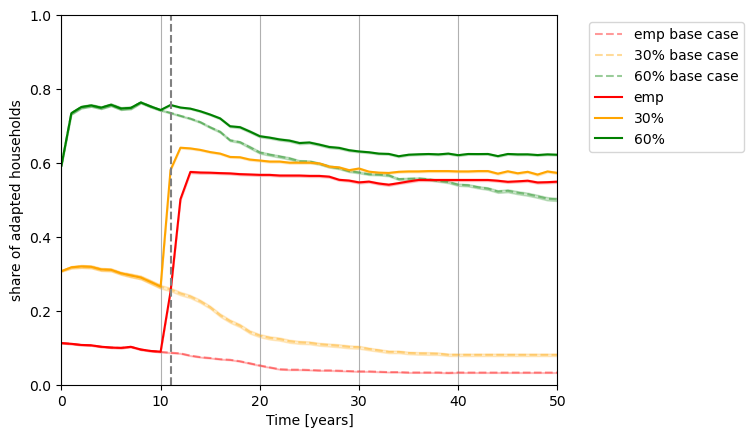

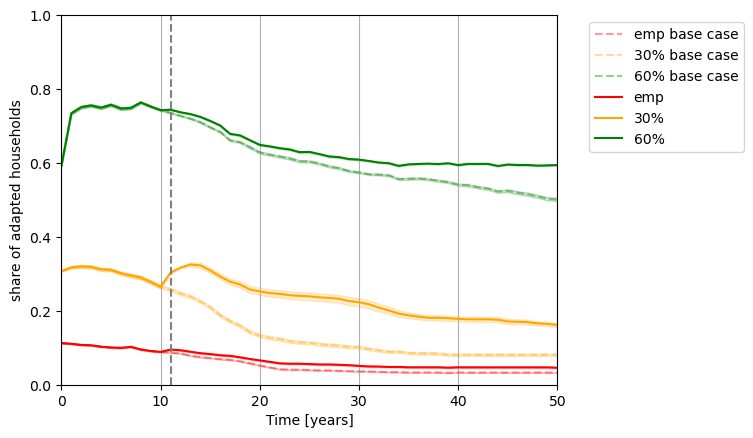

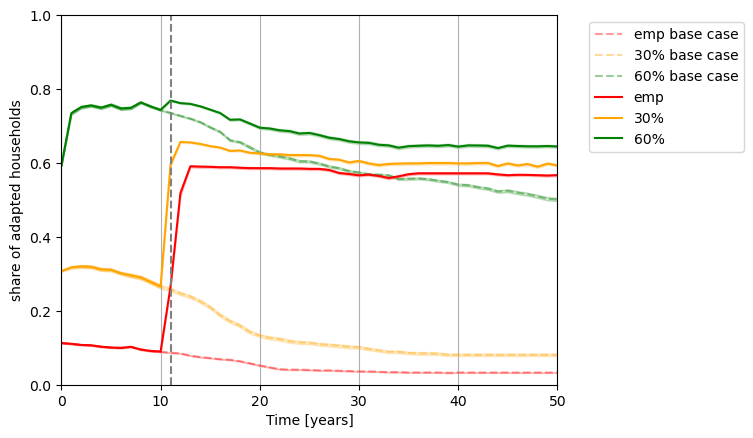

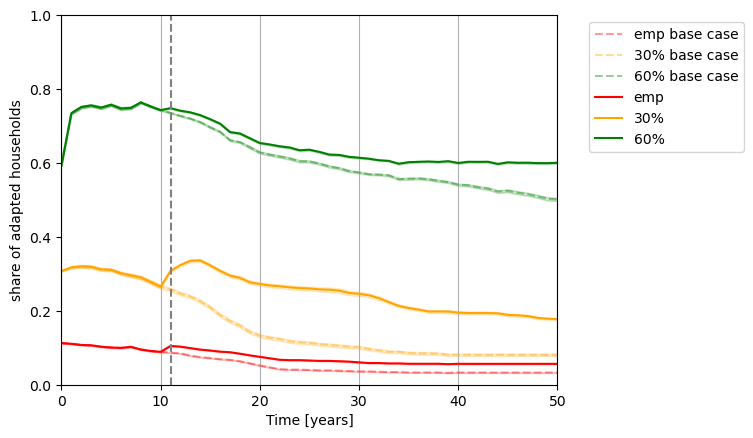

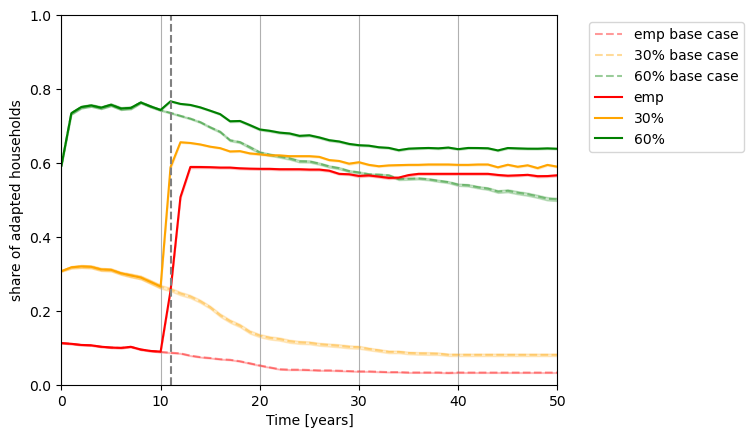

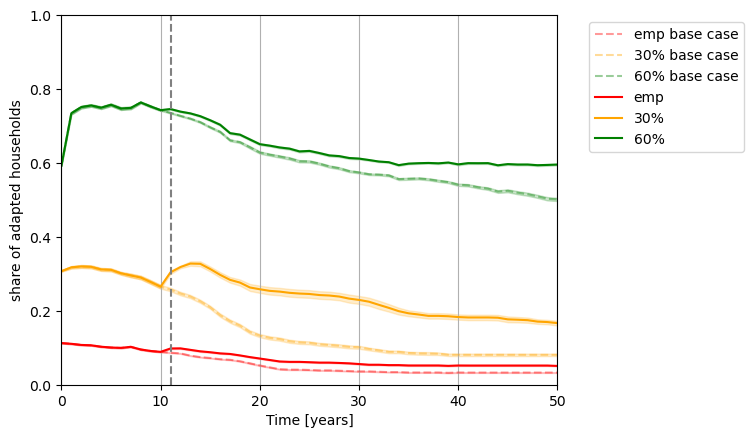

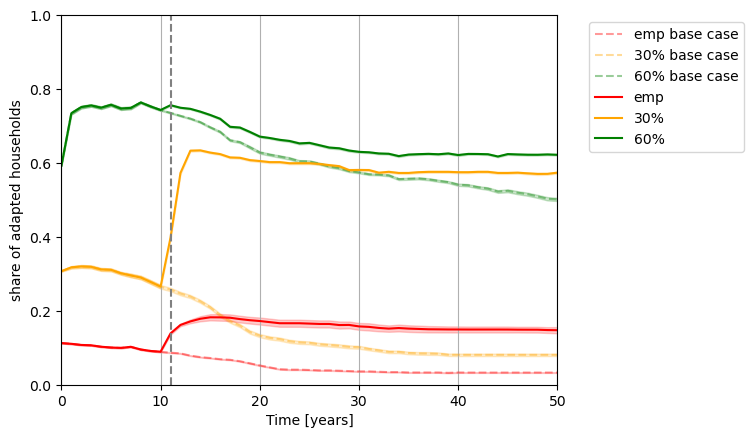

In [43]:
for policy in policy_comb_runs.policy.unique():
    plt.figure()
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'emp base case', color = 'red', alpha = 0.4, linestyle = '--')
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = '30% base case', color = 'orange', alpha = 0.4, linestyle = '--')
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[99]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), label = '60% base case', color = 'green', alpha = 0.4, linestyle = '--')

    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == 'False') & (policy_comb_runs['flood_time'] == '[99]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policy'] == policy)], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'emp', color = 'red')
    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_comb_runs['flood_time'] == '[99]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policy'] == policy)], x='Step', y='fraction_adapted_any', errorbar=('sd'),  label = '30%', color = 'orange')
    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == '0.6') & (policy_comb_runs['flood_time'] == '[99]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policy'] == policy)], x='Step', y='fraction_adapted_any',  errorbar=('sd'),  label = '60%', color = 'green')

    plt.grid(axis = 'x')
    plt.ylim(0, 1)
    plt.xlim(0, 50)
    plt.ylabel('share of adapted households')
    plt.xlabel('Time [years]')
    plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    #plt.title(policy)
    plt.savefig(f'../reports/figures/p_comb_{policy}_no_flood.png', bbox_inches='tight')
    # plt.show()

In [44]:
policy_comb_runs['damage_reduction'] = (policy_comb_runs['cumulative_damage_no_adaptation']-policy_comb_runs['cumulative_damage'])

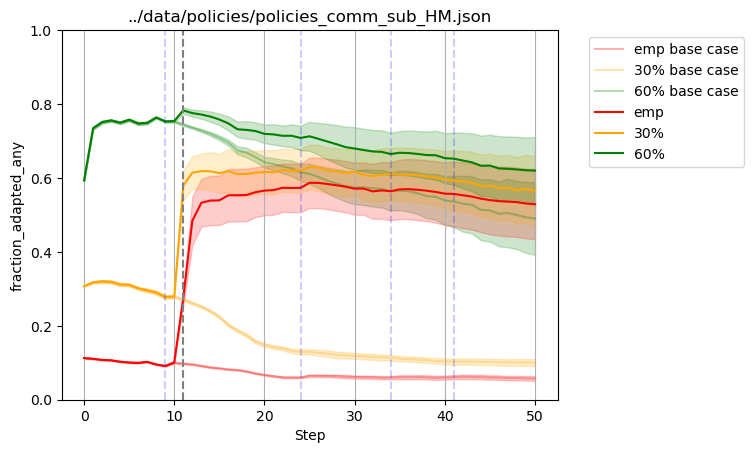

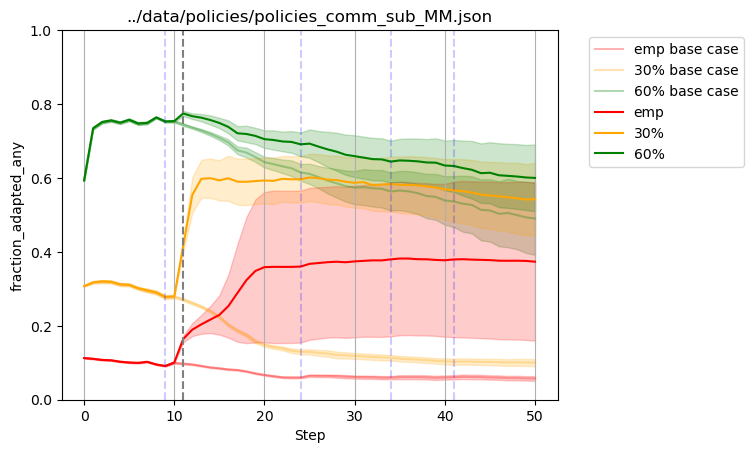

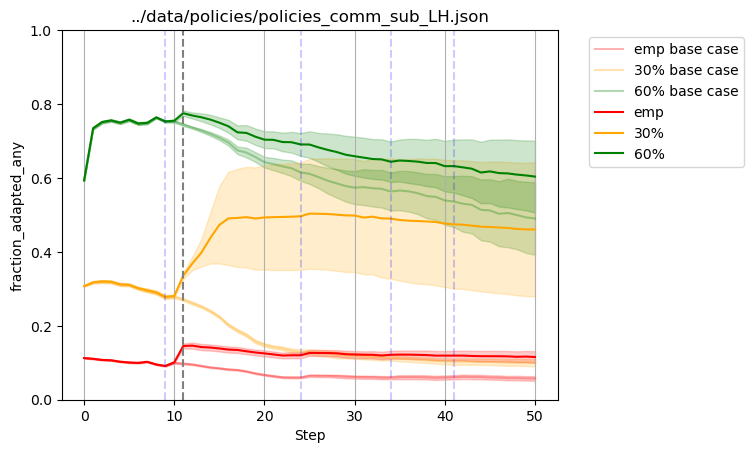

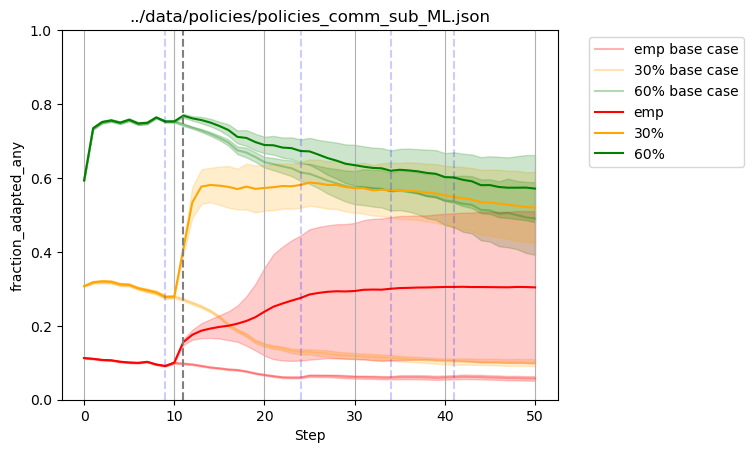

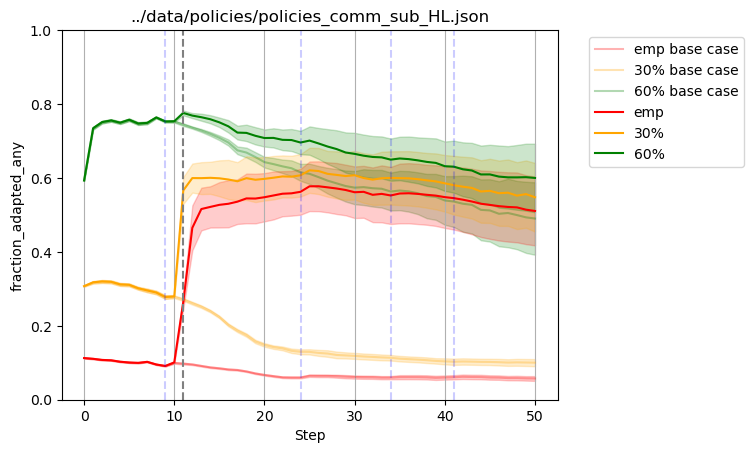

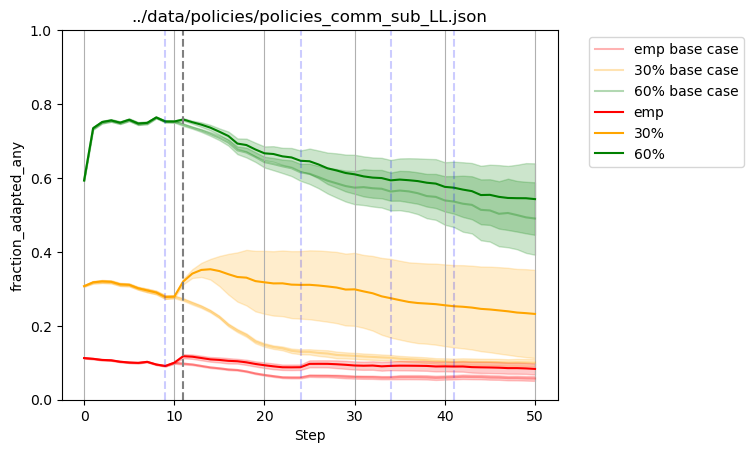

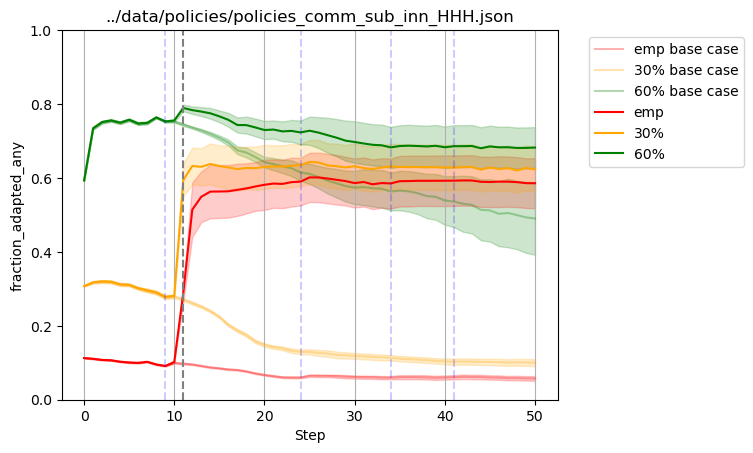

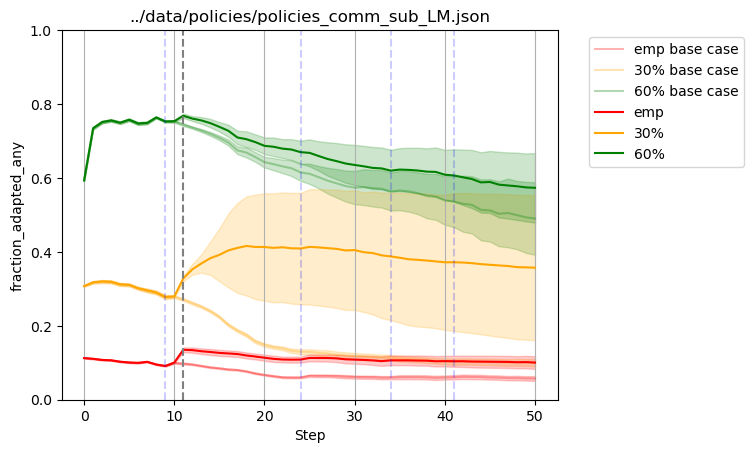

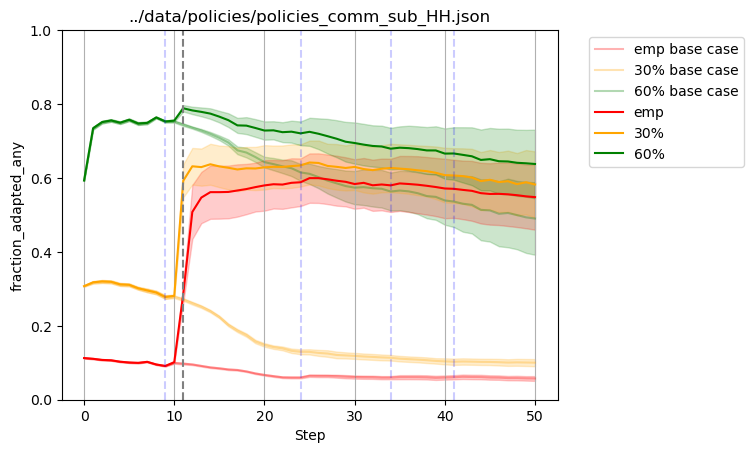

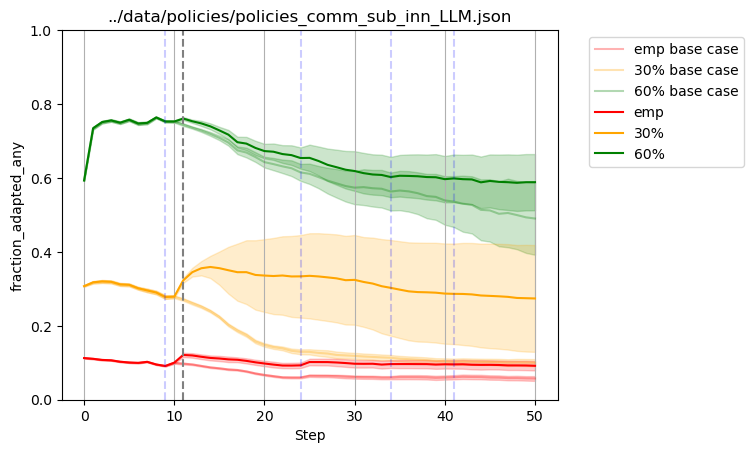

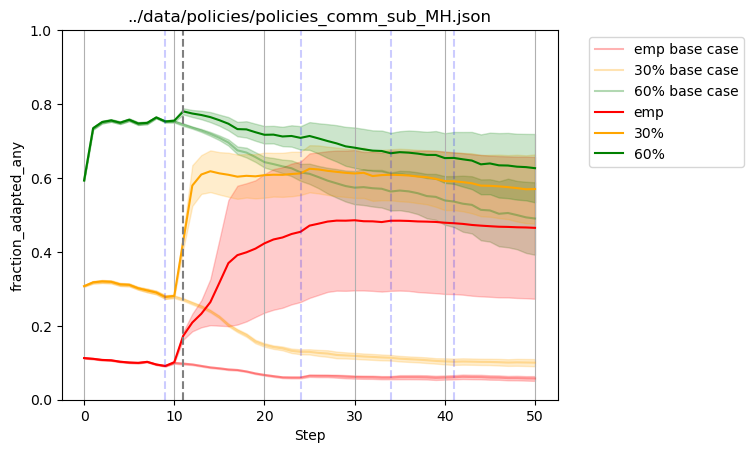

In [45]:
for policy in policy_comb_runs.policies_file_path.unique():
    plt.figure()
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'emp base case', color = 'red', alpha = 0.3)
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = '30% base case', color = 'orange', alpha = 0.3)
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10, 25, 35, 42]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='fraction_adapted_any',  errorbar=('sd'), label = '60% base case', color = 'green', alpha = 0.3)

    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == 'False') & (policy_comb_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policies_file_path'] == policy)], x='Step', y='fraction_adapted_any', errorbar=('sd'), label = 'emp', color = 'red')
    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_comb_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policies_file_path'] == policy)], x='Step', y='fraction_adapted_any', errorbar=('sd'),  label = '30%', color = 'orange')
    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == '0.6') & (policy_comb_runs['flood_time'] == '[10, 25, 35, 42]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policies_file_path'] == policy)], x='Step', y='fraction_adapted_any',  errorbar=('sd'),  label = '60%', color = 'green')

    plt.grid(axis = 'x')
    plt.ylim(0, 1)
    plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
    plt.axvline(9, 0, 1, color = 'blue', alpha = 0.2, linestyle = '--')
    plt.axvline(24, 0, 1, color = 'blue', alpha = 0.2, linestyle = '--')
    plt.axvline(34, 0, 1, color = 'blue', alpha = 0.2, linestyle = '--')
    plt.axvline(41, 0, 1, color = 'blue', alpha = 0.2, linestyle = '--')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(policy)
    plt.show()

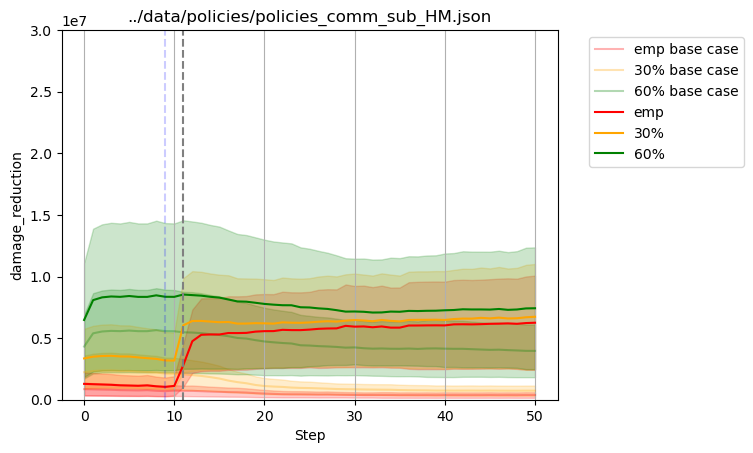

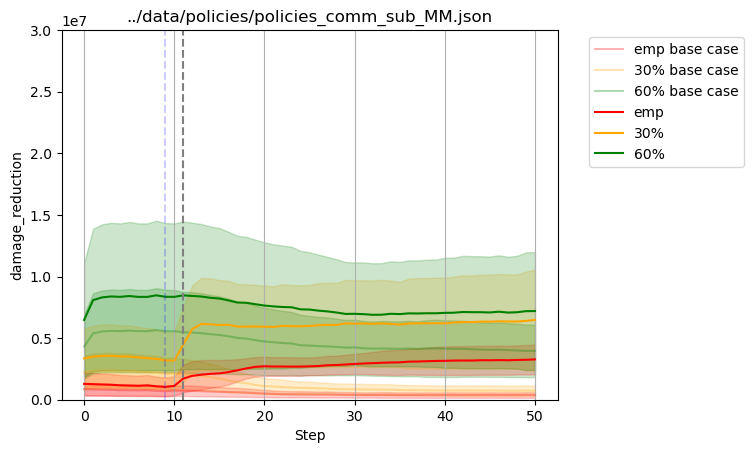

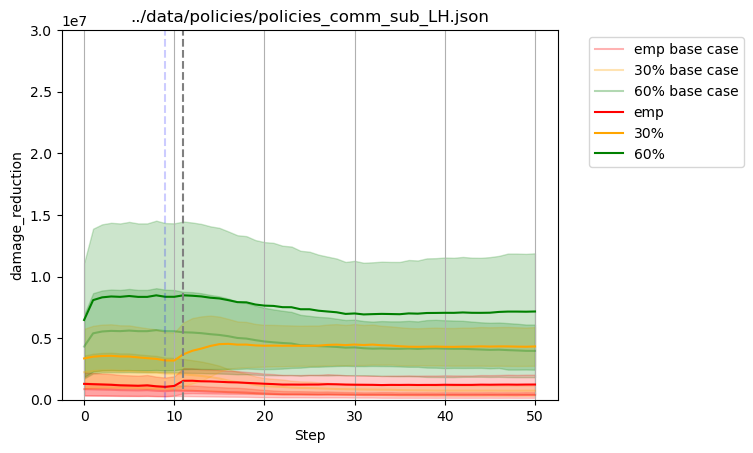

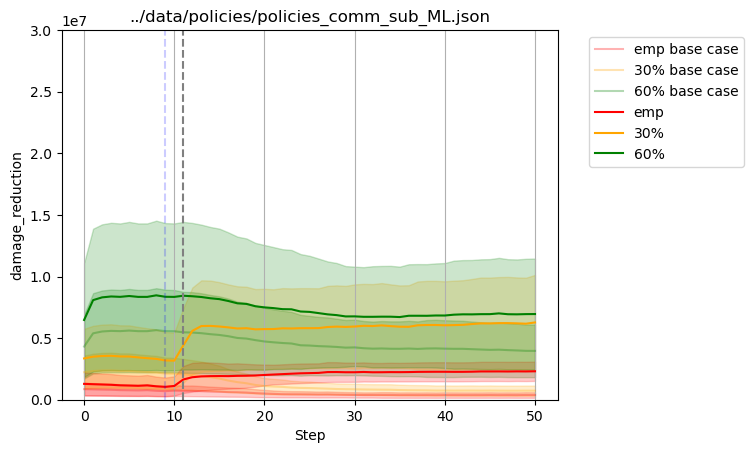

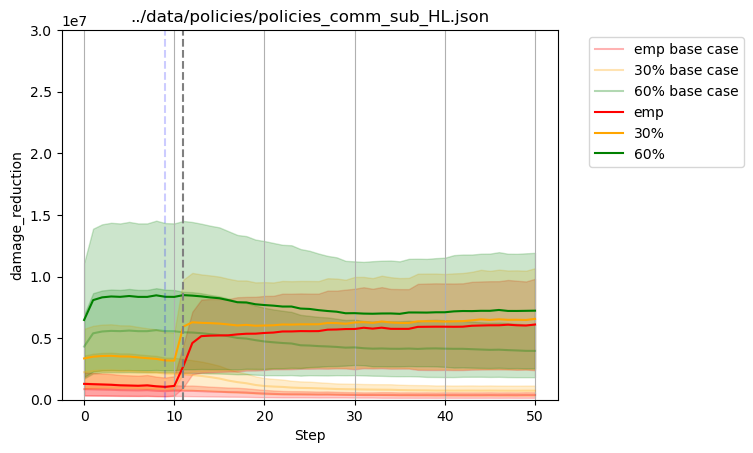

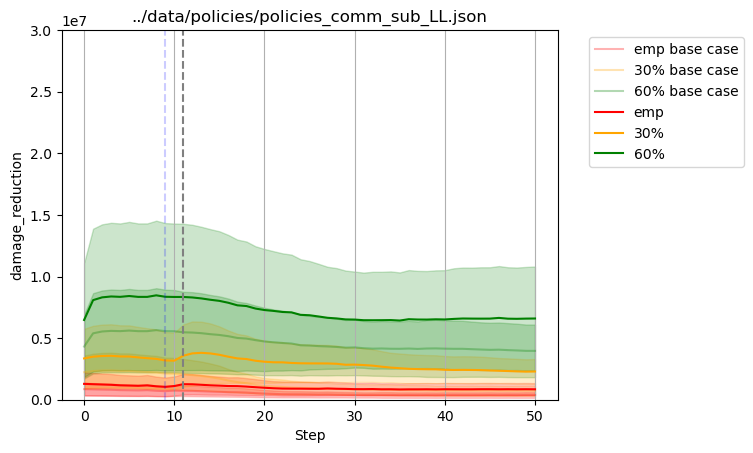

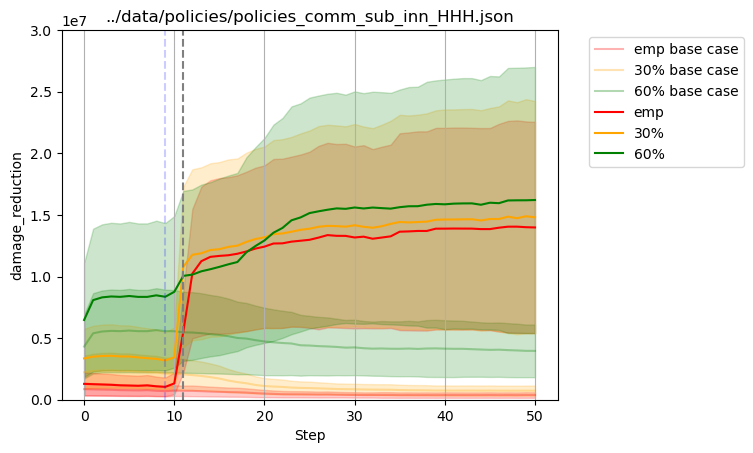

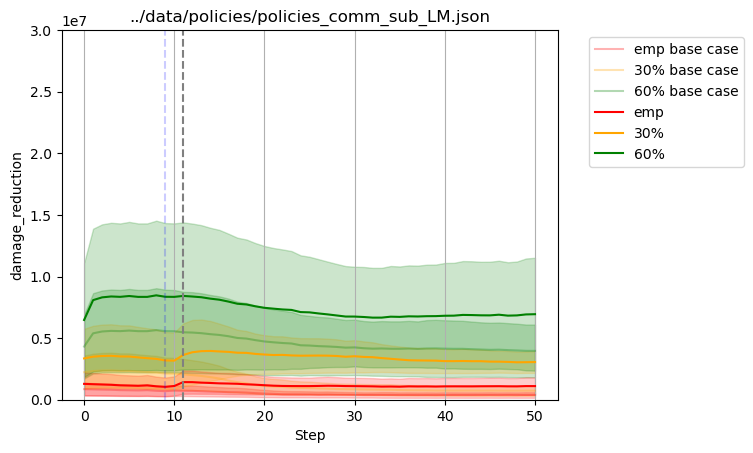

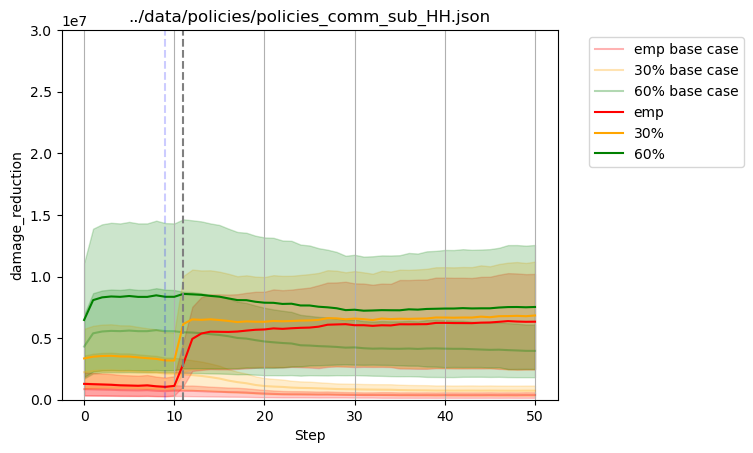

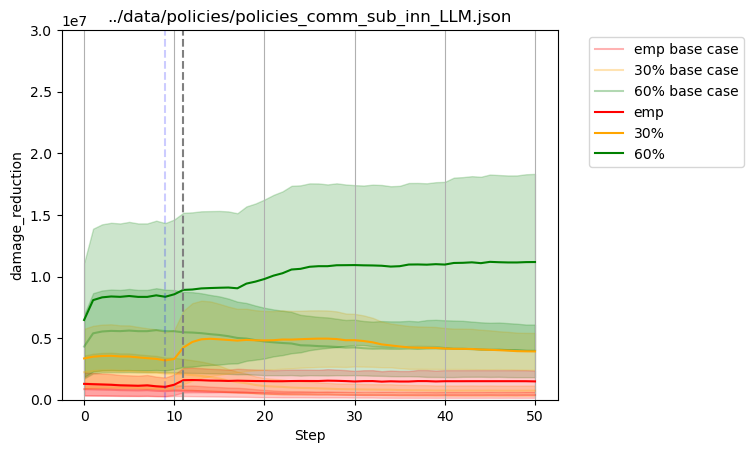

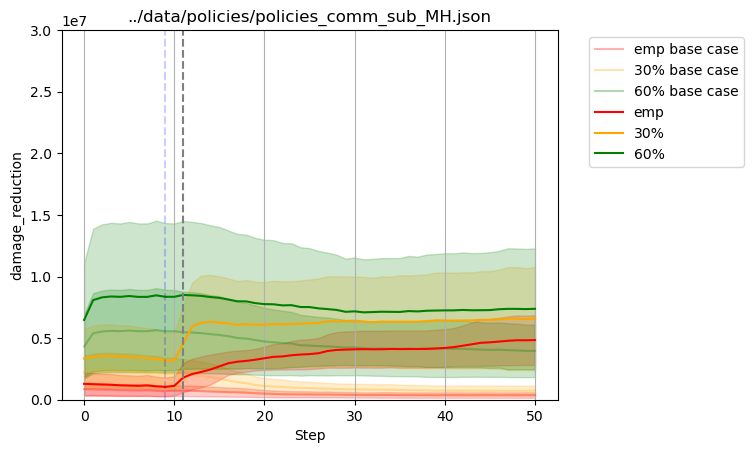

In [46]:
all_three_policies_path_file = ['../data/policies/policies_comm_sub_inn_HHH.json', '../data/policies/policies_comm_sub_inn_LLM.json']
for policy in policy_comb_runs.policies_file_path.unique():
    plt.figure()
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == 'False') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='damage_reduction', errorbar=('sd'), label = 'emp base case', color = 'red', alpha = 0.3)
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.3')  & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='damage_reduction', errorbar=('sd'), label = '30% base case', color = 'orange', alpha = 0.3)
    sns.lineplot(data=base_and_climate_runs.loc[(base_and_climate_runs['set_hh_adapted_at_start'] == '0.6') & (base_and_climate_runs['flood_time'] == '[10]') & (base_and_climate_runs['flood_depth_in_m'] == '[99, 1, 1, 1, 1]')], x='Step', y='damage_reduction',  errorbar=('sd'), label = '60% base case', color = 'green', alpha = 0.3)

    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == 'False') & (policy_comb_runs['flood_time'] == '[10]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policies_file_path'] == policy)], x='Step', y='damage_reduction', errorbar=('sd'), label = 'emp', color = 'red')
    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == '0.3')  & (policy_comb_runs['flood_time'] == '[10]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policies_file_path'] == policy)], x='Step', y='damage_reduction', errorbar=('sd'),  label = '30%', color = 'orange')
    sns.lineplot(data=policy_comb_runs.loc[(policy_comb_runs['set_hh_adapted_at_start'] == '0.6') & (policy_comb_runs['flood_time'] == '[10]') & (policy_comb_runs['policy_activation'] == '[11]')& (policy_comb_runs['policies_file_path'] == policy)], x='Step', y='damage_reduction',  errorbar=('sd'),  label = '60%', color = 'green')

    plt.grid(axis = 'x')
    plt.ylim(0, 3e7)
    plt.axvline(11, 0, 1, color = 'grey', linestyle = '--')
    plt.axvline(9, 0, 1, color = 'blue', alpha = 0.2, linestyle = '--')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(policy)
    plt.show()